In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Data Overview

## Features:
1. **PassengerId:** Unique identifier for each passenger.
2. **Survived:** Indicates whether the passenger survived (1) or not (0).
3. **Pclass:** Ticket class (1st, 2nd, or 3rd class).
4. **Name:** Passenger's name.
5. **Sex:** Passenger's gender (male or female).
6. **Age:** Passenger's age in years.
7. **SibSp:** Number of siblings/spouses aboard the Titanic.
8. **Parch:** Number of parents/children aboard the Titanic.
9. **Ticket:** Ticket number.
10. **Fare:** Passenger fare.
11. **Cabin:** Cabin number.
12. **Embarked:** Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

In [4]:
#Read the training data
train_data = pd.read_csv("train.csv")

#Display the first rows of train data
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
#Display the columns, number of non-null, and Dtype
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
#Read test data and display the first rows
test_data = pd.read_csv("test.csv")
test_data.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [7]:
#Display the columns, number of non-null, and Dtype
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.0+ KB


## Preliminary Statistics

In [8]:
train_data['Survived'].value_counts() / train_data.shape[0] * 100

0    61.616162
1    38.383838
Name: Survived, dtype: float64

In [9]:
# Calculate the mean survival rate grouped by passenger class
train_data.groupby(['Pclass'], as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


People of higher socioeconomic class `Pclass = 1` are more likely to survive with approximately 63% of survival rate.

In [10]:
# Calculate the mean survival rate grouped by gender
train_data.groupby(['Sex'], as_index=False)['Survived'].mean()

,Sex,Survived
0,female,0.742038
1,male,0.188908


Females are more likely to survive with 74% of survival rate.

In [11]:
# Calculate the mean survival rate grouped by SibSp
train_data.groupby(['SibSp'], as_index=False)['Survived'].mean()

,SibSp,Survived
0,0,0.345395
1,1,0.535885
2,2,0.464286
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


Passengers with one or two siblings or spouses aboard were more likely to survive. Also, passengers with zero or greater or equal to three siblings or spouses were less to likely to survive.

In [12]:
# Calculate the mean survival rate grouped by Parch
train_data.groupby(['Parch'], as_index=False)['Survived'].mean()

,Parch,Survived
0,0,0.343658
1,1,0.550847
2,2,0.500000
3,3,0.600000
4,4,0.000000
5,5,0.200000
6,6,0.000000


When `Parch` of a passenger is 1, 2, or 3, they are more likely to survive.


In [13]:
# Calculate the mean survival rate grouped by Parch
train_data.groupby(['Embarked'], as_index=False)['Survived'].agg(['count', 'mean'])

,count,mean
Embarked,,
C,168,0.553571
Q,77,0.389610
S,644,0.336957


When the passenger embarked at the gate C, they are more likely to survive with 55.3% of survival rate.

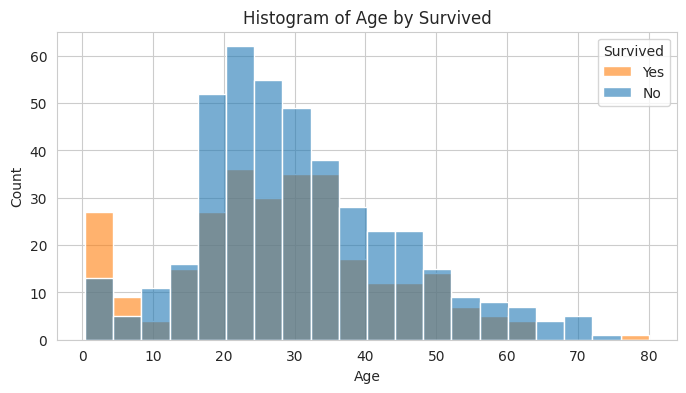

In [14]:
# Age histogram grouped by Survive
# Set the style of the visualization
sns.set_style('whitegrid')

# Create a histogram of the 'Age' variable split by 'Survived'
plt.figure(figsize=(8, 4))
sns.histplot(data=train_data, x='Age', hue='Survived', bins=20, alpha=0.6)
plt.title('Histogram of Age by Survived')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(title='Survived', labels=['Yes', 'No'])
plt.show()

Passengers younger than or equal to 8 years old were the only ones with a higher survival rate than no survival. For all other age groups, they were less likely to survive.

# Features Selection

In [15]:
selected_features = ['Age','Pclass', 'Sex', 'Embarked', 'Parch', 'SibSp', 'Fare']

y = train_data['Survived']

X_train = train_data[selected_features]

X_test = test_data[selected_features]

In [16]:
X_train.shape, y.shape, X_test.shape

((891, 7), (891,), (418, 7))

# Features Preprocessing

Here we handle missing values and tranform and encode the categorical variables to adjust to the model.

## Handling missing values

First, we count the missing value for the selected features and handle it.

In [17]:
# Count the number of missing value for each column
X_train.isnull().sum()

Age         177
Pclass        0
Sex           0
Embarked      2
Parch         0
SibSp         0
Fare          0
dtype: int64

In [18]:
# Fill rows with missing values from Embarked
X_train['Embarked'].fillna("S", inplace=True)
X_test['Embarked'].fillna("S", inplace=True)

In [19]:
# Count the number of missing value for each column
X_test.isnull().sum()

Age         86
Pclass       0
Sex          0
Embarked     0
Parch        0
SibSp        0
Fare         1
dtype: int64

In [21]:
# Fill missing values in the 'Age' column with the median age
X_train['Age'].fillna(X_train['Age'].median(), inplace=True)
X_test['Age'].fillna(X_train['Age'].median(), inplace=True)


print(X_train['Age'].isnull().sum(),X_test['Age'].isnull().sum())

0 0


In [22]:
X_test['Fare'].fillna(X_test['Fare'].median(), inplace=True)

X_test['Fare'].isnull().sum()

0

In [ ]:
# Create bins for the 'Age' column
#bins = [0, 18, 30, 50, 100]
#labels = ['0-18', '18-30', '30-50', '50+']
#X_train['AgeGroup'] = pd.cut(X_train['Age'], bins=bins, labels=labels, right=False)
#X_test['AgeGroup'] = pd.cut(X_test['Age'], bins=bins, labels=labels, right=False)

In [ ]:
#X_train = X_train.drop('Age', axis=1)
#X_test = X_test.drop('Age', axis=1)

In [23]:
X_train

,Age,Pclass,Sex,Embarked,Parch,SibSp,Fare
0,22.0,3,male,S,0,1,7.2500
1,38.0,1,female,C,0,1,71.2833
2,26.0,3,female,S,0,0,7.9250
3,35.0,1,female,S,0,1,53.1000
4,35.0,3,male,S,0,0,8.0500
...,...,...,...,...,...,...,...
886,27.0,2,male,S,0,0,13.0000
887,19.0,1,female,S,0,0,30.0000
888,28.0,3,female,S,2,1,23.4500
889,26.0,1,male,C,0,0,30.0000


## Mapping and Encoding the Categorical features


In [24]:
# Define a function to map 'SibSp' values to groups
def map_sibsp_group(sibsp):
    if sibsp == 0:
        return 'none'
    elif sibsp <= 3:
        return 'few'
    else:
        return 'many'

# Apply the function to create 'SibSp_group' column
X_train['SibSp_group'] = X_train['SibSp'].map(map_sibsp_group)
X_test['SibSp_group'] = X_test['SibSp'].map(map_sibsp_group)

# Drop the 'SibSp' column
X_train.drop('SibSp', axis=1, inplace=True)
X_test.drop('SibSp', axis=1, inplace=True)

# Use the same function to map 'Parch' since it also have the same unique values as 'SibSp'
# Apply the function to create 'Parch_group' column
X_train['Parch_group'] = X_train['Parch'].map(map_sibsp_group)
X_test['Parch_group'] = X_test['Parch'].map(map_sibsp_group)

# Drop the 'Parch' column
X_train.drop('Parch', axis=1, inplace=True)
X_test.drop('Parch', axis=1, inplace=True)

print("X_train:")
print(X_train)

print("\nX_test:")
print(X_test)

X_train:
      Age  Pclass     Sex Embarked     Fare SibSp_group Parch_group
0    22.0       3    male        S   7.2500         few        none
1    38.0       1  female        C  71.2833         few        none
2    26.0       3  female        S   7.9250        none        none
3    35.0       1  female        S  53.1000         few        none
4    35.0       3    male        S   8.0500        none        none
..    ...     ...     ...      ...      ...         ...         ...
886  27.0       2    male        S  13.0000        none        none
887  19.0       1  female        S  30.0000        none        none
888  28.0       3  female        S  23.4500         few         few
889  26.0       1    male        C  30.0000        none        none
890  32.0       3    male        Q   7.7500        none        none

[891 rows x 7 columns]

X_test:
      Age  Pclass     Sex Embarked      Fare SibSp_group Parch_group
0    34.5       3    male        Q    7.8292        none        none
1   

In [25]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          891 non-null    float64
 1   Pclass       891 non-null    int64  
 2   Sex          891 non-null    object 
 3   Embarked     891 non-null    object 
 4   Fare         891 non-null    float64
 5   SibSp_group  891 non-null    object 
 6   Parch_group  891 non-null    object 
dtypes: float64(2), int64(1), object(4)
memory usage: 48.9+ KB


In [26]:
# Perform one-hot encoding
X_train_encoded = pd.get_dummies(X_train, drop_first='True')

X_train_encoded

,Age,Pclass,Fare,Sex_male,Embarked_Q,Embarked_S,SibSp_group_many,SibSp_group_none,Parch_group_many,Parch_group_none
0,22.0,3,7.2500,1,0,1,0,0,0,1
1,38.0,1,71.2833,0,0,0,0,0,0,1
2,26.0,3,7.9250,0,0,1,0,1,0,1
3,35.0,1,53.1000,0,0,1,0,0,0,1
4,35.0,3,8.0500,1,0,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...
886,27.0,2,13.0000,1,0,1,0,1,0,1
887,19.0,1,30.0000,0,0,1,0,1,0,1
888,28.0,3,23.4500,0,0,1,0,0,0,0
889,26.0,1,30.0000,1,0,0,0,1,0,1


In [27]:
# Perform one-hot encoding
X_test_encoded = pd.get_dummies(X_test, drop_first='True')

X_test_encoded


,Age,Pclass,Fare,Sex_male,Embarked_Q,Embarked_S,SibSp_group_many,SibSp_group_none,Parch_group_many,Parch_group_none
0,34.5,3,7.8292,1,1,0,0,1,0,1
1,47.0,3,7.0000,0,0,1,0,0,0,1
2,62.0,2,9.6875,1,1,0,0,1,0,1
3,27.0,3,8.6625,1,0,1,0,1,0,1
4,22.0,3,12.2875,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
413,28.0,3,8.0500,1,0,1,0,1,0,1
414,39.0,1,108.9000,0,0,0,0,1,0,1
415,38.5,3,7.2500,1,0,1,0,1,0,1
416,28.0,3,8.0500,1,0,1,0,1,0,1


In [28]:
X_train_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               891 non-null    float64
 1   Pclass            891 non-null    int64  
 2   Fare              891 non-null    float64
 3   Sex_male          891 non-null    uint8  
 4   Embarked_Q        891 non-null    uint8  
 5   Embarked_S        891 non-null    uint8  
 6   SibSp_group_many  891 non-null    uint8  
 7   SibSp_group_none  891 non-null    uint8  
 8   Parch_group_many  891 non-null    uint8  
 9   Parch_group_none  891 non-null    uint8  
dtypes: float64(2), int64(1), uint8(7)
memory usage: 27.1 KB


In [29]:

X_train_encoded.shape, y.shape, X_test_encoded.shape

((891, 10), (891,), (418, 10))

# Model Building

In [30]:
# Import packages for data modeling
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from scipy import stats
from sklearn.model_selection import GridSearchCV

In [ ]:
"""rf = RandomForestClassifier(random_state=42)

cv_params = {'max_depth': [2,3,4,5, None],
             'min_samples_leaf': [1,2,3],
             'min_samples_split': [2,3,4],
             'max_features': [None, 1, 2, 3, 4, 5],
             'n_estimators': [100]
             }

scoring = {'accuracy', 'precision', 'recall', 'f1'}

rf_cv = GridSearchCV(rf, cv_params, scoring=scoring, cv=5, refit='f1')

rf_cv.fit(X_train_encoded, y)

"""

In [31]:
xgb = XGBClassifier(objective='binary:logistic', random_state=42)

cv_params = {'max_depth': [4,5,6,7,8],
             'min_child_weight': [1,2,3,4,5],
             'learning_rate': [0.1, 0.2, 0.3],
             'n_estimators': [100]
             }

scoring = {'accuracy', 'precision', 'recall', 'f1'}

xgb_cv = GridSearchCV(xgb, cv_params, scoring=scoring, cv=5, refit='f1')

In [32]:
%%time
xgb_cv.fit(X_train_encoded, y)

CPU times: user 31.1 s, sys: 661 ms, total: 31.7 s
Wall time: 17.6 s


GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             param_grid={'learning_rate': [0.1, 0.2, 0.3],
                         'max_depth': [4, 5, 6, 7, 8],
                         'min_child_weight': [1, 2, 3, 4, 5],
                         'n_estimators': [100]},
             refit='f1', scoring={'recall', 'accuracy', 'f1', 'precision'})

In [33]:
xgb_cv.best_params_

{'learning_rate': 0.3,
 'max_depth': 5,
 'min_child_weight': 5,
 'n_estimators': 100}

In [34]:
xgb_cv.best_score_

0.7812999402628436

In [35]:
def make_results(model_name, model_object):
    '''
    Accepts as arguments a model name (your choice - string) and
    a fit GridSearchCV model object.

    Returns a pandas df with the F1, recall, precision, and accuracy scores
    for the model with the best mean F1 score across all validation folds.
    '''

    # Get all the results from the CV and put them in a df
    cv_results = pd.DataFrame(model_object.cv_results_)

    # Isolate the row of the df with the max(mean f1 score)
    best_estimator_results = cv_results.iloc[cv_results['mean_test_f1'].idxmax(), :]

    # Extract accuracy, precision, recall, and f1 score from that row
    f1 = best_estimator_results.mean_test_f1
    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    # Create table of results
    table = pd.DataFrame({'Model': [model_name],
                          'F1': [f1],
                          'Recall': [recall],
                          'Precision': [precision],
                          'Accuracy': [accuracy]
                         }
                        )

    return table

In [36]:
# Make a results table for the rf_cv model using above function
rf_cv_results = make_results('XGBoost', xgb_cv)
rf_cv_results

,Model,F1,Recall,Precision,Accuracy
0,XGBoost,0.7813,0.739685,0.829825,0.840663


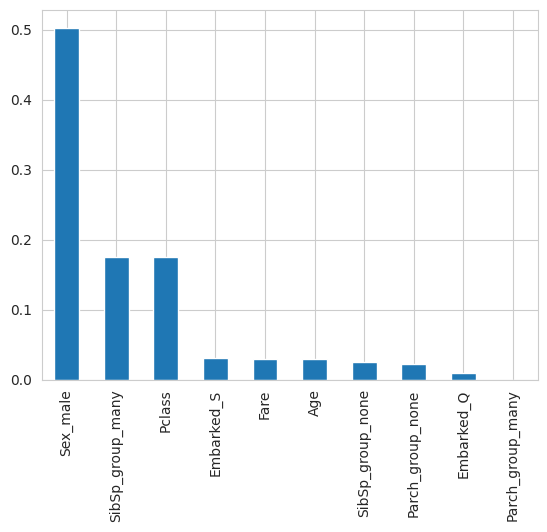

In [37]:
importances = xgb_cv.best_estimator_.feature_importances_

forest_importances = pd.Series(importances, index=xgb_cv.feature_names_in_).sort_values(ascending=False)

fig, ax = plt.subplots()
forest_importances.plot.bar(ax=ax);

In [38]:
# Make predictions on the test data
predictions = xgb_cv.predict(X_test_encoded)

In [39]:
test_data.PassengerId, predictions.shape

(0       892
 1       893
 2       894
 3       895
 4       896
        ... 
 413    1305
 414    1306
 415    1307
 416    1308
 417    1309
 Name: PassengerId, Length: 418, dtype: int64,
 (418,))

In [40]:
predictions

array([0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,

In [ ]:
output = pd.DataFrame({'PassengerId': test_data.PassengerId, 'Survived': predictions})
output.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")

# Using Naive Bayes Model

In [41]:
from sklearn.naive_bayes import GaussianNB # Import Gaussian Naive Bayes for classification
# Create Naive Bayes classifer object
clf = GaussianNB()

# Train Naive Bayes Classifer
clf = clf.fit(X_train_encoded, y)

In [42]:
#Predict the response for train dataset
y_pred = clf.predict(X_train_encoded)

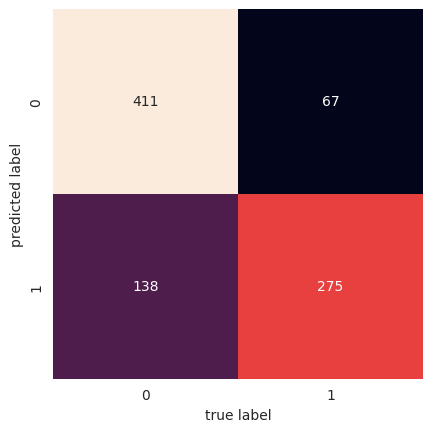

In [43]:
# Calculating Confusion Matrix
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(y, y_pred)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [44]:
# Showing the performance of the model. How often is the classifier correct? (accuracy)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.75      0.80       549
           1       0.67      0.80      0.73       342

    accuracy                           0.77       891
   macro avg       0.76      0.78      0.76       891
weighted avg       0.79      0.77      0.77       891



# Using Data Normalization (Transformation)

In [45]:
X_train_encoded

,Age,Pclass,Fare,Sex_male,Embarked_Q,Embarked_S,SibSp_group_many,SibSp_group_none,Parch_group_many,Parch_group_none
0,22.0,3,7.2500,1,0,1,0,0,0,1
1,38.0,1,71.2833,0,0,0,0,0,0,1
2,26.0,3,7.9250,0,0,1,0,1,0,1
3,35.0,1,53.1000,0,0,1,0,0,0,1
4,35.0,3,8.0500,1,0,1,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...
886,27.0,2,13.0000,1,0,1,0,1,0,1
887,19.0,1,30.0000,0,0,1,0,1,0,1
888,28.0,3,23.4500,0,0,1,0,0,0,0
889,26.0,1,30.0000,1,0,0,0,1,0,1


In [51]:
from sklearn import preprocessing
scaler = preprocessing.MinMaxScaler() #Min-Max scaler
d = scaler.fit_transform(X_train_encoded)
X_train_encoded_norm = pd.DataFrame(d, columns=X_train_encoded.columns)

In [52]:
X_train_encoded_norm

,Age,Pclass,Fare,Sex_male,Embarked_Q,Embarked_S,SibSp_group_many,SibSp_group_none,Parch_group_many,Parch_group_none
0,0.271174,1.0,0.014151,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.472229,0.0,0.139136,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.321438,1.0,0.015469,0.0,0.0,1.0,0.0,1.0,0.0,1.0
3,0.434531,0.0,0.103644,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.434531,1.0,0.015713,1.0,0.0,1.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
886,0.334004,0.5,0.025374,1.0,0.0,1.0,0.0,1.0,0.0,1.0
887,0.233476,0.0,0.058556,0.0,0.0,1.0,0.0,1.0,0.0,1.0
888,0.346569,1.0,0.045771,0.0,0.0,1.0,0.0,0.0,0.0,0.0
889,0.321438,0.0,0.058556,1.0,0.0,0.0,0.0,1.0,0.0,1.0


In [55]:
# Train Naive Bayes Classifer
clf = clf.fit(X_train_encoded_norm, y)

#Predict the response for train dataset
y_pred = clf.predict(X_train_encoded_norm)

# Showing the performance of the model. How often is the classifier correct? (accuracy)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.75      0.80       549
           1       0.67      0.80      0.73       342

    accuracy                           0.77       891
   macro avg       0.76      0.78      0.76       891
weighted avg       0.79      0.77      0.77       891



In [59]:
#Using Standard Scaler
scaler = preprocessing.StandardScaler()
d = scaler.fit_transform(X_train_encoded)
X_train_encoded_norm = pd.DataFrame(d, columns=X_train_encoded.columns)
X_train_encoded_norm

,Age,Pclass,Fare,Sex_male,Embarked_Q,Embarked_S,SibSp_group_many,SibSp_group_none,Parch_group_many,Parch_group_none
0,-0.565736,0.827377,-0.502445,0.737695,-0.307562,0.615838,-0.186663,-1.465746,-0.10654,0.560499
1,0.663861,-1.566107,0.786845,-1.355574,-0.307562,-1.623803,-0.186663,-1.465746,-0.10654,0.560499
2,-0.258337,0.827377,-0.488854,-1.355574,-0.307562,0.615838,-0.186663,0.682247,-0.10654,0.560499
3,0.433312,-1.566107,0.420730,-1.355574,-0.307562,0.615838,-0.186663,-1.465746,-0.10654,0.560499
4,0.433312,0.827377,-0.486337,0.737695,-0.307562,0.615838,-0.186663,0.682247,-0.10654,0.560499
...,...,...,...,...,...,...,...,...,...,...
886,-0.181487,-0.369365,-0.386671,0.737695,-0.307562,0.615838,-0.186663,0.682247,-0.10654,0.560499
887,-0.796286,-1.566107,-0.044381,-1.355574,-0.307562,0.615838,-0.186663,0.682247,-0.10654,0.560499
888,-0.104637,0.827377,-0.176263,-1.355574,-0.307562,0.615838,-0.186663,-1.465746,-0.10654,-1.784124
889,-0.258337,-1.566107,-0.044381,0.737695,-0.307562,-1.623803,-0.186663,0.682247,-0.10654,0.560499


In [60]:
# Train Naive Bayes Classifer
clf = clf.fit(X_train_encoded_norm, y)

#Predict the response for train dataset
y_pred = clf.predict(X_train_encoded_norm)

# Showing the performance of the model. How often is the classifier correct? (accuracy)
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.75      0.80       549
           1       0.67      0.80      0.73       342

    accuracy                           0.77       891
   macro avg       0.76      0.78      0.76       891
weighted avg       0.79      0.77      0.77       891

